# Independent MACD: Supertrend and pivots

## Baseline correction
Conclusions about the actual strategy are suspended. This replay changes the signal sample, execution, sizing, allocation, costs and trade management. Its negative results do not contradict the supplied positive benchmark or the actual MACD paper book. The live book reconciles to +Rs 1.86 L marked profit, including +Rs 3.41 L unrealised and -Rs 1.55 L realised; its durable fill history starts on 29 September. Read `RECONCILIATION.md` and the updated `FINDINGS.md`. Tables below remain simplified-rule diagnostics, not validated recommendations.

## Context & Methods
Compare completed 30-minute MACD zero-cross rules with independently calculated Supertrend and prior-period pivots. Read `PLAN.md` and `FINDINGS.md` for rules, selection and censoring.

### Key Assumptions
Four-lot signal replay, a shared four-session cap, conservative five-minute OHLC execution, current lot inventory, scenario fees, and no deployed ranker or pyramiding. The cash replay uses whole lots up to Rs 1 lakh tickets. No trading settings were changed.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np
import matplotlib.pyplot as plt
ROOT=Path('/Users/ramachandran/MACD-mini-ADV/research/supertrend_pivots_20261003')
summary=pd.read_csv(ROOT/'results.csv')
capital=pd.read_csv(ROOT/'capital_results.csv')
books=json.loads((ROOT/'capital_books.json').read_text())
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white'})

## Data
The immutable local five-minute extract comes from the original application candle table. Missing or incomplete compared paths are excluded and counted. Source fields and hash are in `source_manifest.json`; expiry recovery provenance is separate.

In [2]:
quality=json.loads((ROOT/'quality.json').read_text())
pd.DataFrame.from_dict(quality['counts'],orient='index',columns=['Count'])

,Count
option_series,6248
too_short,1002
missing_expiry_series,88
crosses,10295
late_entry,1413
incomplete_signal,1015
illiquid_entry,1904
censored,2188
eligible,3298
missing_entry,477


## Results
### Entry filters
Conditional mean returns can improve because fewer signals are traded. They must be compared with total opportunity returns and a funded book, and tested across sides.

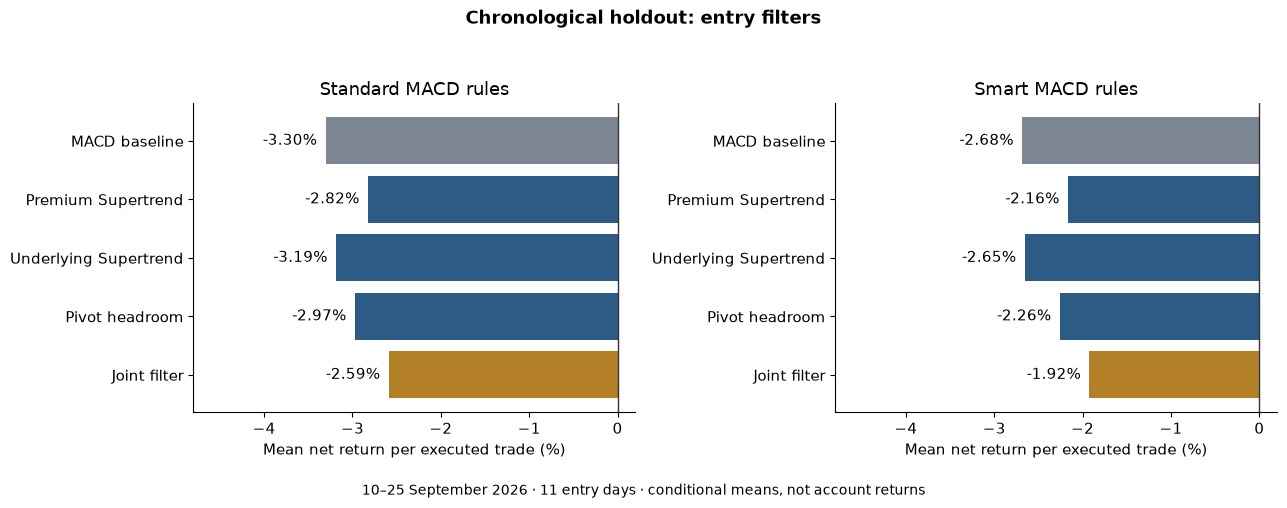

In [3]:
rules=['baseline','premium_st30_10_3_align','spot_st30_10_3_align','spot_daily_room','combined_st_pivot']
labels=['MACD baseline','Premium Supertrend','Underlying Supertrend','Pivot headroom','Joint filter']
fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True)
for ax,lane in zip(axes,['standard','smart']):
    block=summary[(summary.lane==lane)&(summary.period=='holdout')].set_index('rule').loc[rules]
    values=block.mean_net_pct.to_numpy()
    ax.barh(labels,values,color=['#7d8794']+['#2c5c85']*3+['#b48128'])
    for i,v in enumerate(values):ax.text(v-.1,i,f'{v:+.2f}%',ha='right',va='center')
    ax.axvline(0,color='#30343a',lw=1);ax.invert_yaxis();ax.set_xlim(-4.8,.2)
    ax.set_title(lane.capitalize()+' MACD rules');ax.set_xlabel('Mean net return per executed trade (%)')
fig.suptitle('Chronological holdout: entry filters',fontweight='bold')
fig.text(.5,.01,'10–25 September 2026 · 11 entry days · conditional means, not account returns',ha='center',fontsize=10)
fig.tight_layout(rect=[0,.05,1,.94]);fig.savefig(ROOT/'entry_comparison.png',dpi=150);plt.show()

In [4]:
summary[(summary.period=='holdout')&summary.rule.isin(rules)][['lane','rule','trades','mean_net_pct','CE_mean_pct','PE_mean_pct','daily_delta_t','p_holm','weekly_p_holm']]

,lane,rule,trades,mean_net_pct,CE_mean_pct,PE_mean_pct,daily_delta_t,p_holm,weekly_p_holm
2,standard,baseline,1844,-3.304176,-6.520122,1.472068,0.000000,NaN,NaN
8,standard,combined_st_pivot,1335,-2.590172,-6.326332,4.108342,1.439731,1.0,1.0
41,standard,premium_st30_10_3_align,1584,-2.824241,-5.972740,2.216458,1.335377,1.0,1.0
107,standard,spot_daily_room,1628,-2.972161,-6.640128,2.560874,1.532410,1.0,1.0
116,standard,spot_st30_10_3_align,1664,-3.185305,-6.263852,1.985267,1.068959,1.0,1.0
170,smart,baseline,1823,-2.683308,-7.887803,5.055982,0.000000,NaN,NaN
176,smart,combined_st_pivot,1324,-1.922125,-7.210562,7.530261,1.177605,1.0,1.0
209,smart,premium_st30_10_3_align,1571,-2.164582,-7.389803,6.200961,1.328926,1.0,1.0
275,smart,spot_daily_room,1609,-2.257850,-7.635645,5.863375,1.358569,1.0,1.0
284,smart,spot_st30_10_3_align,1649,-2.654861,-7.639053,5.681745,0.774406,1.0,1.0


### Sequential cash books
Independent Rs 50 lakh books, whole lots, tickets up to Rs 1 lakh, simultaneous-contract exclusion after funding, and cash released at partial exits. Daily equity includes the runoff after the last entry.

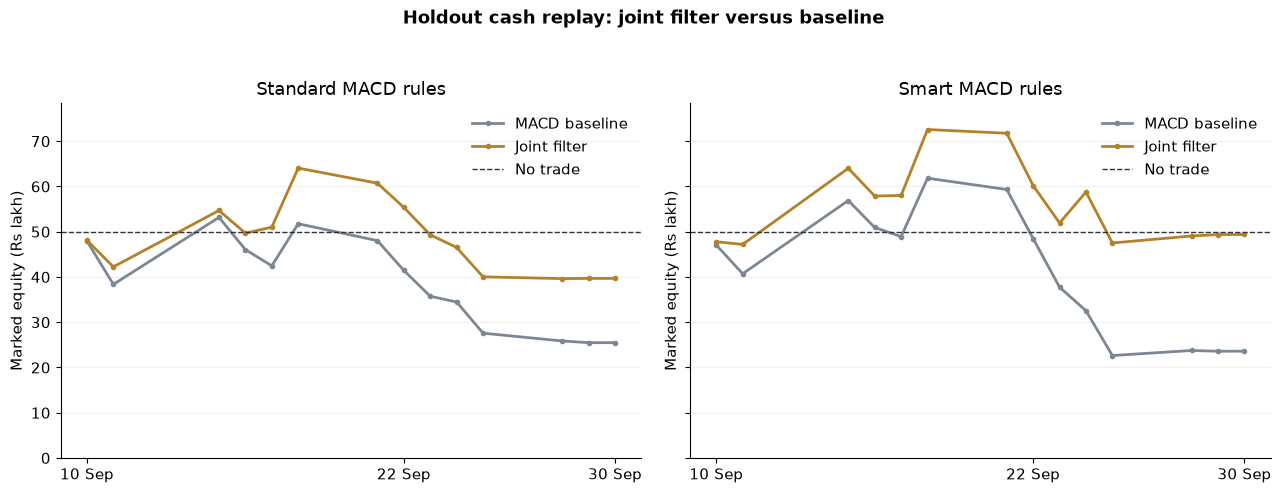

In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,lane in zip(axes,['standard','smart']):
    for rule,label,color in [('baseline','MACD baseline','#7d8794'),('combined_st_pivot','Joint filter','#b48128')]:
        marks=books[f'{lane}|holdout|{rule}']['marks']
        dates=pd.to_datetime([m['day'] for m in marks]);equity=np.array([m['equity'] for m in marks])/100000
        ax.plot(dates,equity,label=label,color=color,lw=2,marker='o',markersize=3)
    ax.axhline(50,color='#30343a',ls='--',label='No trade',lw=1)
    ax.set_title(lane.capitalize()+' MACD rules');ax.set_ylabel('Marked equity (Rs lakh)');ax.set_ylim(0, max(m['equity']/100000 for key,b in books.items() if '|holdout|' in key and (key.endswith('|baseline') or key.endswith('|combined_st_pivot')) for m in b['marks'])*1.08);ax.legend(frameon=False)
    ticks=dates[[0,len(dates)//2,-1]];ax.set_xticks(ticks);ax.set_xticklabels([d.strftime('%d %b') for d in ticks]);ax.grid(axis='y',alpha=.2)
fig.suptitle('Holdout cash replay: joint filter versus baseline',fontweight='bold')
fig.tight_layout(rect=[0,0,1,.94]);fig.savefig(ROOT/'capital_comparison.png',dpi=150);plt.show()

In [6]:
capital[(capital.period=='holdout')&capital.rule.isin(['baseline','combined_st_pivot'])][['lane','rule','pnl','max_drawdown','entries','daily_difference_t','p_holm']]

,lane,rule,pnl,max_drawdown,entries,daily_difference_t,p_holm
12,standard,baseline,-2.451747e+06,2.768531e+06,860,0.000000,NaN
19,standard,combined_st_pivot,-1.031594e+06,2.442608e+06,899,1.871786,1.0
36,smart,baseline,-2.639188e+06,3.918621e+06,801,0.000000,NaN
43,smart,combined_st_pivot,-6.137354e+04,2.507015e+06,891,2.022269,1.0


### Cost and walk-forward checks
The forward selector purges four entry sessions and uses only resolved training labels. Only seven entry days are available across two test blocks.

In [7]:
pd.read_csv(ROOT/'capital_cost_sensitivity.csv')

,lane,slippage_bps,rule,pnl,max_drawdown,entries
0,standard,5,baseline,-2.451747e+06,2.768531e+06,860
1,standard,5,combined_st_pivot,-1.031594e+06,2.442608e+06,899
2,standard,5,spot_st30_7_2_align,-2.479502e+06,2.991556e+06,892
3,standard,25,baseline,-2.605311e+06,2.834891e+06,839
4,standard,25,combined_st_pivot,-1.495646e+06,2.741507e+06,885
5,standard,25,spot_st30_7_2_align,-2.548913e+06,2.920892e+06,885
6,standard,50,baseline,-3.026391e+06,3.163662e+06,814
7,standard,50,combined_st_pivot,-1.751339e+06,2.832438e+06,869
8,standard,50,spot_st30_7_2_align,-2.686231e+06,2.957601e+06,849
9,smart,5,baseline,-2.639188e+06,3.918621e+06,801


In [8]:
pd.read_csv(ROOT/'walk_forward.csv')

,lane,train_end,test_start,test_end,rule,baseline_units,selected_units,delta_units
0,standard,2026-09-09,2026-09-17,2026-09-23,premium_weekly_inside_cpr,-35.660514,-14.184089,21.476425
1,standard,2026-09-17,2026-09-24,2026-09-25,premium_weekly_inside_cpr,0.425510,2.460849,2.035338
2,smart,2026-09-09,2026-09-17,2026-09-23,spot_weekly_aligned_p,-30.656015,-41.958118,-11.302103
3,smart,2026-09-17,2026-09-24,2026-09-25,spot_weekly_aligned_p,4.823385,5.963988,1.140603


## Takeaways
Keep the engine unchanged. Conclusions about Supertrend/pivots on the actual strategy, including the earlier joint-filter preference, are suspended until baseline parity is established. Match event selection, minute-level trade management, ranking, dispersion sizing and chronological cash accounting before testing one overlay at a time. Negative returns here describe only the simplified replay. Consult `RECONCILIATION.md` and `FINDINGS.md`.